# CM laser, space charge first: beam − no beam → map and keff → gain structure → static model

**Why this order.** Beam − no beam, with both runs field on and corrected with the same static model, cancels:
- the static distortion (field cage, frames, E×B with the TPC placement);
- the truth pattern;
- field off.

What is left is the space charge and its correction alone, so this comparison pins the space-charge map and keff
without any static-model error. Only after that do the absolute references (field off, CM truth) come in: at the
space-charge keff, whatever they still show is the static model.

**Criterion.** Δφ(R) = RΔφ/R of beam − no beam must be flat in R. A constant Δφ is a rotation between the two runs and
is free. A slope in Δφ is a sagitta (5290 µm per mrad/cm), and a 1/R shape is a DCA.

**Data.** For the space-charge scan, the absscan ring medians of every beam block (6 runs, 17 blocks) for all α, z and
keff points, minus the no-beam run (75073 before the IFC change, 83319 after) at the same z. Both are matched to field
off, which cancels in the difference. The truth-matched no-beam rings are not usable: 75073 picks wrong stripes and
83319 has no truth matches. Sections 2–4 use the per-cluster `data_v2` (`make_v2_data.py`, `make_v2_iter.py`,
`make_v2_cdb.py`).

**Plan (to rerun as results come):**
1. Space charge only: α, b (one for both sides, then per side and per run), linearity in the current.
2. Gain structure in beam − no beam: module charges (`TPC_PHGarfield_ModuleGainTune_v35`, reference `nobeam`) at the
   space-charge b, then a validation scan.
3. Static model at the space-charge keff: no beam vs field off / truth; beam vs field off / truth. Tilt, z, IFC, and the
   missing static piece.
4. Tracks: keff₀ per |η|, CDB keff, charge balance.

In [1]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt
import scplots as sp, v2plots as v, cmplots as c
plt.rcParams['figure.dpi'] = 72
def show(figs):
    for f in figs:
        display(f)
    plt.close('all')
D = sp.data()

## 1. Space charge only (beam − no beam)
### 1a. Map shape α and keff b
χ² of a flat Δφ(R) over the 11 blocks of the 795xx runs and both sides, at the best b, for every α and z. The right
panel shows χ² vs b at z −40.

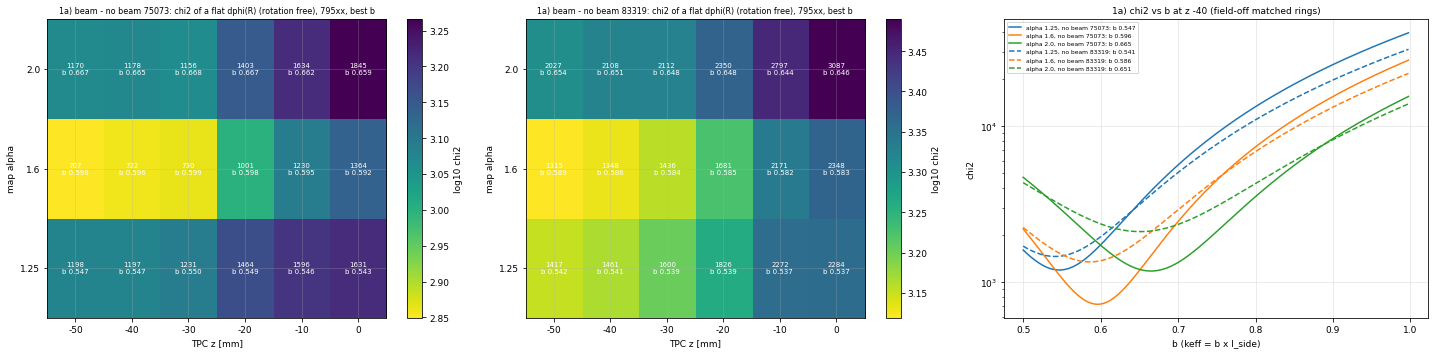

no beam 75073: alpha 1.25: best b 0.547, chi2    1197  (z -40; z dependence: -50: 1198, -40: 1197, -30: 1231, -20: 1464, -10: 1596, 0: 1631)
no beam 75073: alpha  1.6: best b 0.596, chi2     722  (z -40; z dependence: -50: 707, -40: 722, -30: 730, -20: 1001, -10: 1230, 0: 1364)
no beam 75073: alpha  2.0: best b 0.665, chi2    1178  (z -40; z dependence: -50: 1170, -40: 1178, -30: 1156, -20: 1403, -10: 1634, 0: 1845)
no beam 83319: alpha 1.25: best b 0.541, chi2    1461  (z -40; z dependence: -50: 1417, -40: 1461, -30: 1600, -20: 1826, -10: 2272, 0: 2284)
no beam 83319: alpha  1.6: best b 0.586, chi2    1348  (z -40; z dependence: -50: 1315, -40: 1348, -30: 1436, -20: 1681, -10: 2171, 0: 2348)
no beam 83319: alpha  2.0: best b 0.651, chi2    2108  (z -40; z dependence: -50: 2027, -40: 2108, -30: 2112, -20: 2350, -10: 2797, 0: 3087)


In [2]:
f, res = sp.sec1_scan(); show(f)
for nb in sp.NB_RUNS:
    for al in D.alphas:
        b, c2, _ = res[(nb, al, -40)]
        print(f"no beam {nb}: alpha {al:4}: best b {b:.3f}, chi2 {c2:7.0f}  (z -40; z dependence: "
              + ", ".join(f"{z}: {res[(nb, al, z)][1]:.0f}" for z in D.zs) + ")")

### 1b. Δφ(R) at the best b
Per run, for both no-beam references (795xx at the joint b, high lumi at its own b); for 79513/0, b ± 10 %.

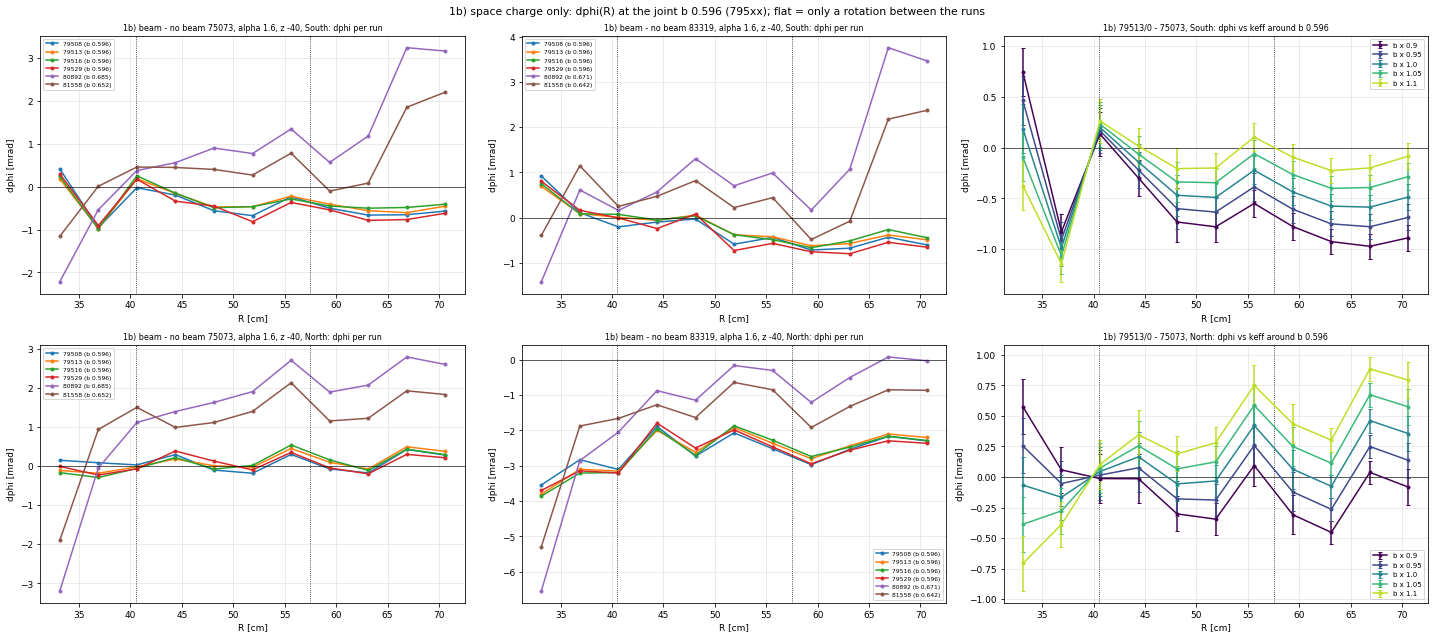

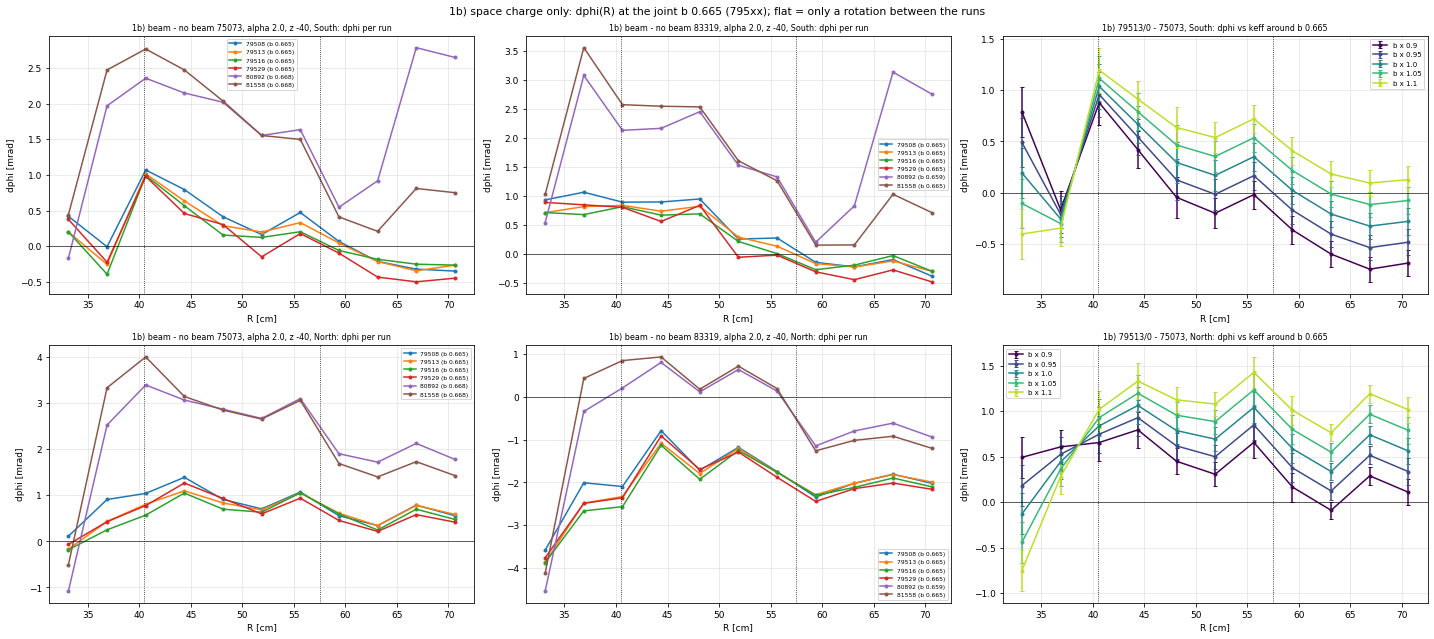

joint b (795xx, no beam 75073): alpha 1.6 -> 0.596, alpha 2.0 -> 0.665


In [3]:
AL = 1.6      # best alpha of 1a; set to 2.0 to see the current production map
f, b16 = sp.sec1_profiles(al=AL); show(f)
f, b20 = sp.sec1_profiles(al=2.0); show(f)
print(f"joint b (795xx, no beam 75073): alpha 1.6 -> {b16:.3f}, alpha 2.0 -> {b20:.3f}")

### 1c. keff vs the GEM current, North / South
The b per run (one b for both sides) against the side current: a flat b means keff is linear in the current. Per side
(free N/S): the North/South ratio should be 1 if the keff ratio follows the GEM currents.

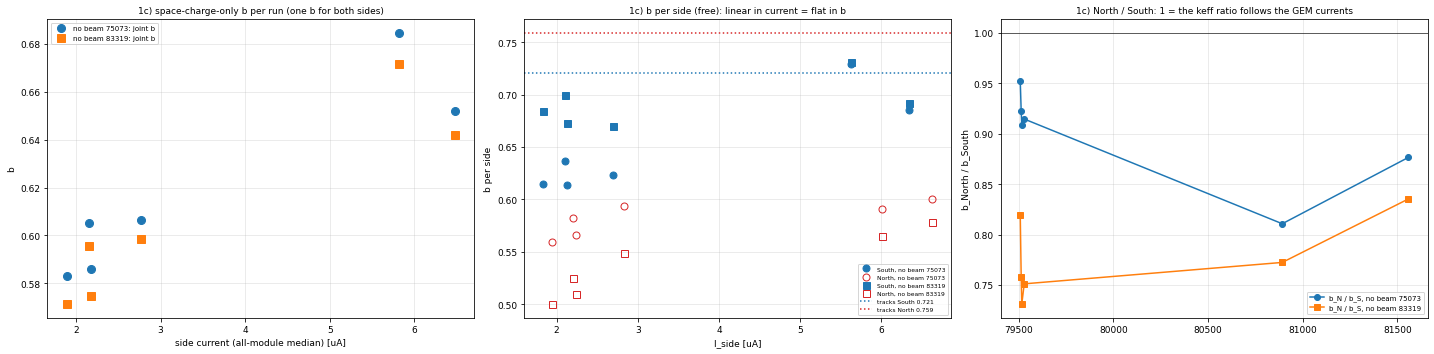

alpha 1.6:
  no beam 75073 run 79508: b 0.606  (South 0.623, North 0.594, N/S 0.952)  I_S 2.70 I_N 2.83 uA
  no beam 75073 run 79513: b 0.586  (South 0.614, North 0.566, N/S 0.922)  I_S 2.12 I_N 2.24 uA
  no beam 75073 run 79516: b 0.583  (South 0.615, North 0.559, N/S 0.909)  I_S 1.84 I_N 1.94 uA
  no beam 75073 run 79529: b 0.605  (South 0.637, North 0.583, N/S 0.915)  I_S 2.10 I_N 2.20 uA
  no beam 75073 run 80892: b 0.685  (South 0.729, North 0.591, N/S 0.811)  I_S 5.63 I_N 6.01 uA
  no beam 75073 run 81558: b 0.652  (South 0.685, North 0.601, N/S 0.876)  I_S 6.34 I_N 6.62 uA
  no beam 83319 run 79508: b 0.599  (South 0.670, North 0.549, N/S 0.820)  I_S 2.70 I_N 2.83 uA
  no beam 83319 run 79513: b 0.575  (South 0.672, North 0.510, N/S 0.758)  I_S 2.12 I_N 2.24 uA
  no beam 83319 run 79516: b 0.571  (South 0.684, North 0.500, N/S 0.731)  I_S 1.84 I_N 1.94 uA
  no beam 83319 run 79529: b 0.596  (South 0.699, North 0.525, N/S 0.751)  I_S 2.10 I_N 2.20 uA
  no beam 83319 run 80892: b 

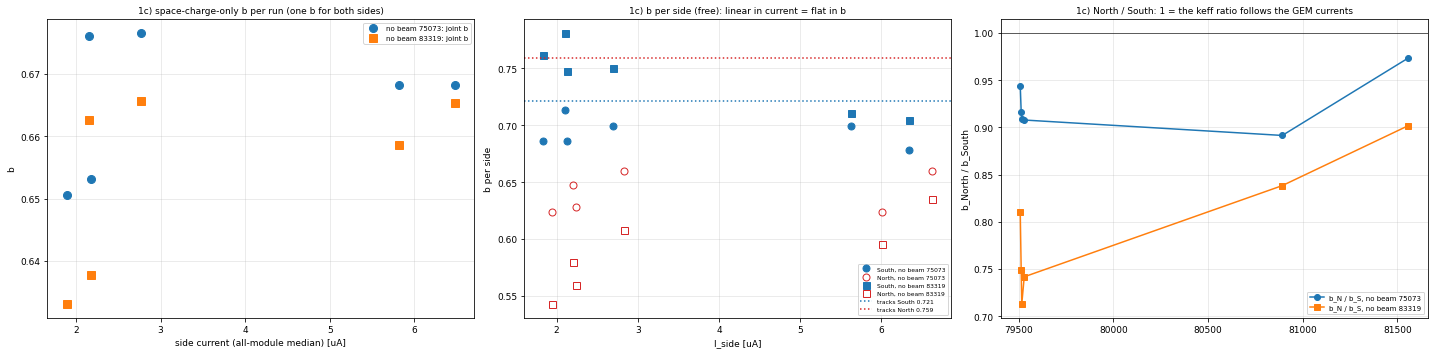

alpha 2.0:
  no beam 75073 run 79508: b 0.677  (South 0.699, North 0.660, N/S 0.944)  I_S 2.70 I_N 2.83 uA
  no beam 75073 run 79513: b 0.653  (South 0.686, North 0.628, N/S 0.916)  I_S 2.12 I_N 2.24 uA
  no beam 75073 run 79516: b 0.651  (South 0.686, North 0.624, N/S 0.908)  I_S 1.84 I_N 1.94 uA
  no beam 75073 run 79529: b 0.676  (South 0.714, North 0.648, N/S 0.908)  I_S 2.10 I_N 2.20 uA
  no beam 75073 run 80892: b 0.668  (South 0.699, North 0.623, N/S 0.891)  I_S 5.63 I_N 6.01 uA
  no beam 75073 run 81558: b 0.668  (South 0.678, North 0.660, N/S 0.973)  I_S 6.34 I_N 6.62 uA
  no beam 83319 run 79508: b 0.666  (South 0.750, North 0.608, N/S 0.810)  I_S 2.70 I_N 2.83 uA
  no beam 83319 run 79513: b 0.638  (South 0.748, North 0.560, N/S 0.748)  I_S 2.12 I_N 2.24 uA
  no beam 83319 run 79516: b 0.633  (South 0.761, North 0.543, N/S 0.713)  I_S 1.84 I_N 1.94 uA
  no beam 83319 run 79529: b 0.663  (South 0.781, North 0.579, N/S 0.742)  I_S 2.10 I_N 2.20 uA
  no beam 83319 run 80892: b 

In [4]:
for al in (1.6, 2.0):
    f, rows = sp.sec1_keff(al=al); show(f)
    print(f"alpha {al}:")
    for nb, run, bj, bS, bN, IS, IN in rows:
        print(f"  no beam {nb} run {run}: b {bj:.3f}  (South {bS:.3f}, North {bN:.3f}, N/S {bN/bS:.3f})  I_S {IS:.2f} I_N {IN:.2f} uA")

### 1d. Space charge only vs tracks and the CDB keff
Tracks (79513, charge-odd rDCA0 = 0): b ≈ 0.72 South / 0.76 North. CDB keff (production): b ≈ 0.74 / 0.70. The
space-charge-only b depends on α (section 1a); the flat-Δφ criterion weighs the whole R shape (DCA and slope), while the
track charge balance is mostly the slope (sagitta).

In [5]:
for al in (1.6, 2.0):
    for nb in sp.NB_RUNS:
        bf = D.best_b(0, -40, al, nb=nb)[0]
        # b where the space-charge-only sagitta (dphi slope) is zero, joint 795xx
        sags = []
        for b in sp.BS:
            s_ = []
            for run, blk in D.blocks:
                if run in sp.LOW:
                    for s in (0, 1):
                        dP, e = D.prof(0, run, blk, -40, al, s, D.a_of_b(run, blk, s, b), nb)
                        if dP is not None:
                            s_.append(D.criteria(dP, e)[2])
            sags.append(np.nanmean(s_))
        sags = np.array(sags); i = int(np.nanargmin(np.abs(sags)))
        print(f"alpha {al}, no beam {nb}: flat-dphi b {bf:.3f} | zero-sagitta b {sp.BS[i]:.3f}  (tracks 0.72 S / 0.76 N, CDB ~0.74 S / 0.70 N, laser absolute {v.B_LOW:.3f})")

alpha 1.6, no beam 75073: flat-dphi b 0.596 | zero-sagitta b 0.595  (tracks 0.72 S / 0.76 N, CDB ~0.74 S / 0.70 N, laser absolute 0.843)
alpha 1.6, no beam 83319: flat-dphi b 0.586 | zero-sagitta b 0.605  (tracks 0.72 S / 0.76 N, CDB ~0.74 S / 0.70 N, laser absolute 0.843)
alpha 2.0, no beam 75073: flat-dphi b 0.665 | zero-sagitta b 0.715  (tracks 0.72 S / 0.76 N, CDB ~0.74 S / 0.70 N, laser absolute 0.843)
alpha 2.0, no beam 83319: flat-dphi b 0.651 | zero-sagitta b 0.727  (tracks 0.72 S / 0.76 N, CDB ~0.74 S / 0.70 N, laser absolute 0.843)


### 1e. 1D projections: RΔφ, Δφ and dR
All clusters (rings 33–71 cm) for beam − no beam (75073, 83319), beam − field off and beam vs truth. Stages: no
correction, static only, α 1.6 and α 2.0 at the space-charge-only b, α 2.0 at the CDB keff, the default CDB map at the CDB
keff, and α 2.0 at the laser-absolute b. Low lumi first, then high lumi.

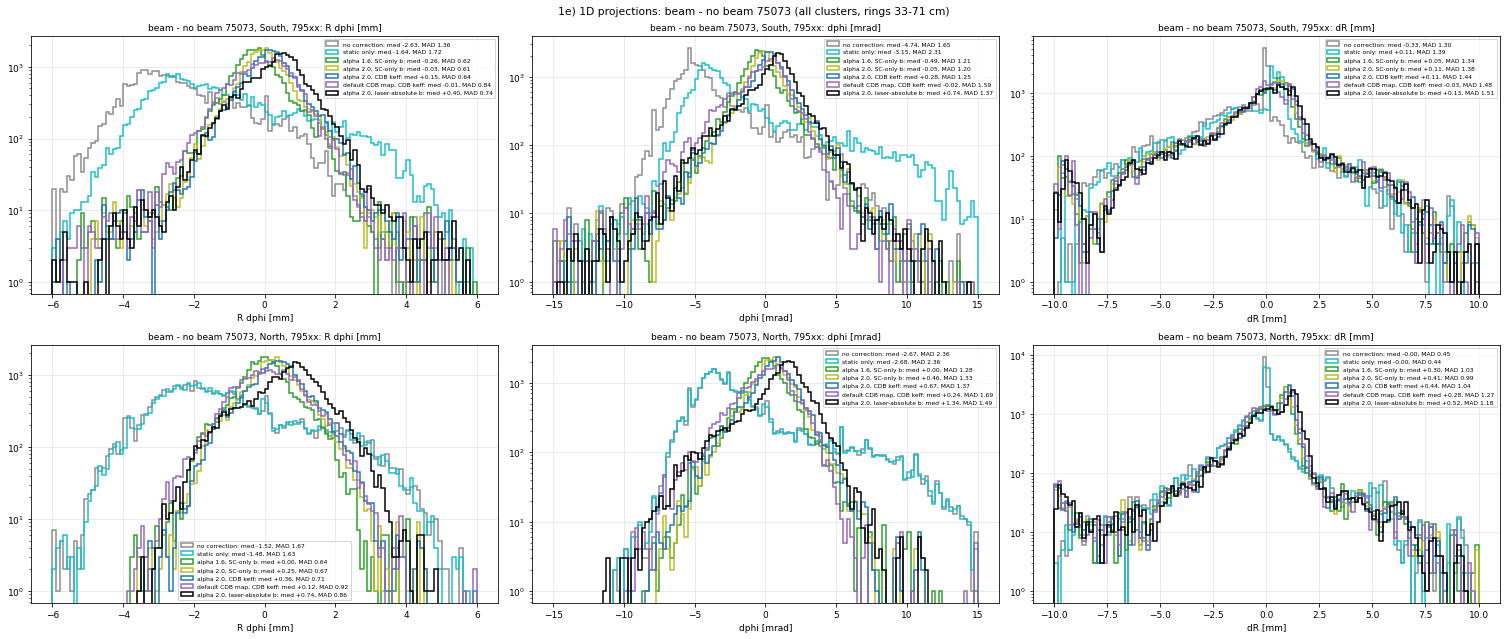

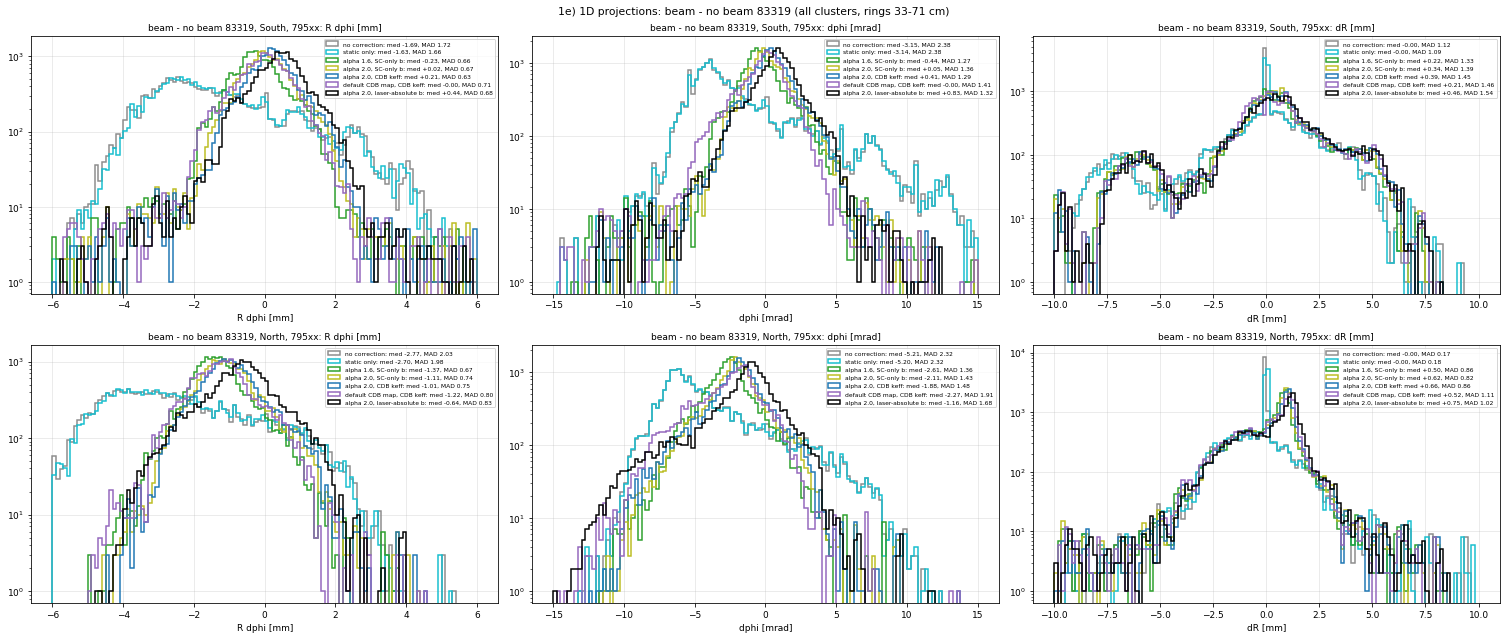

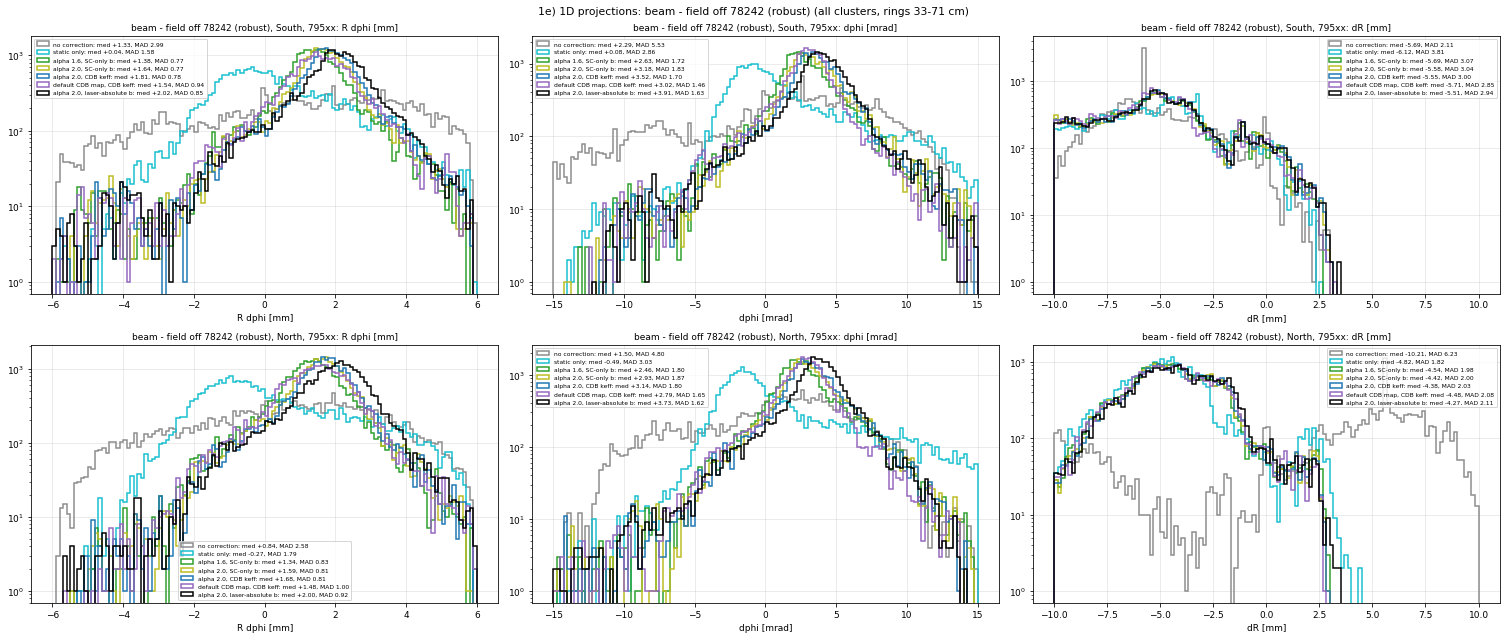

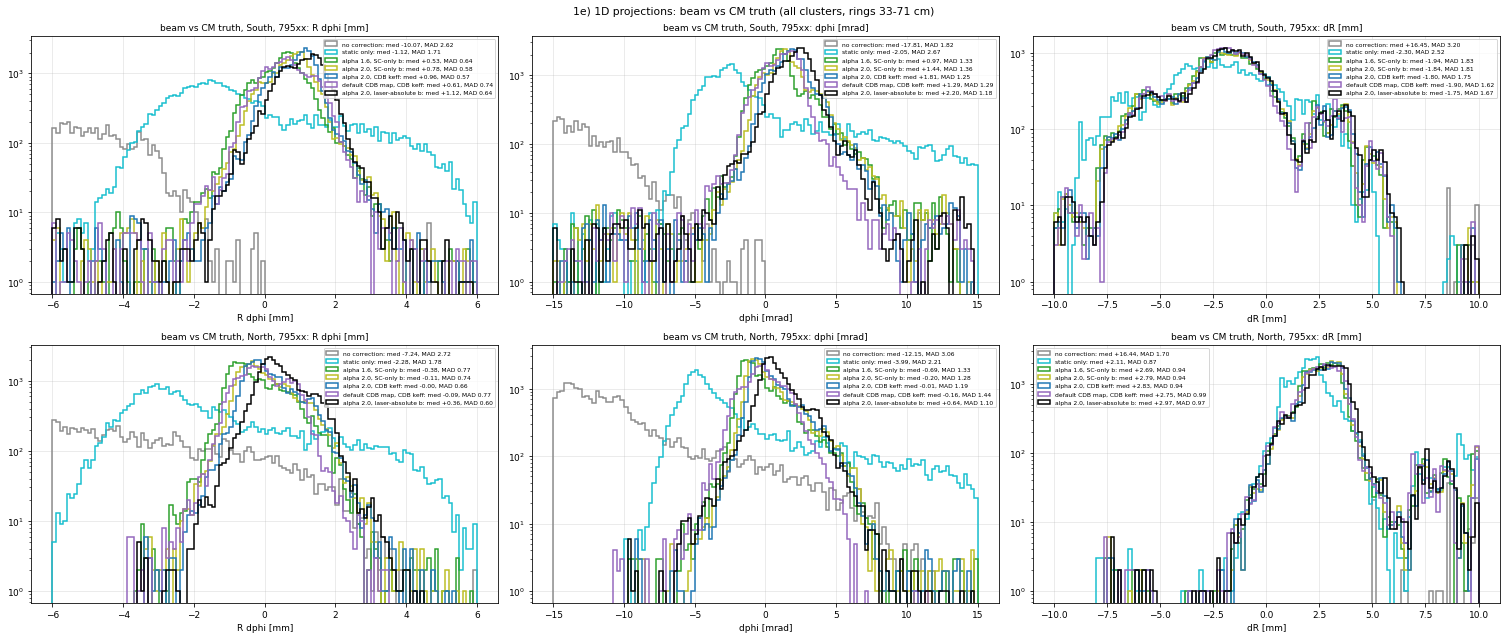

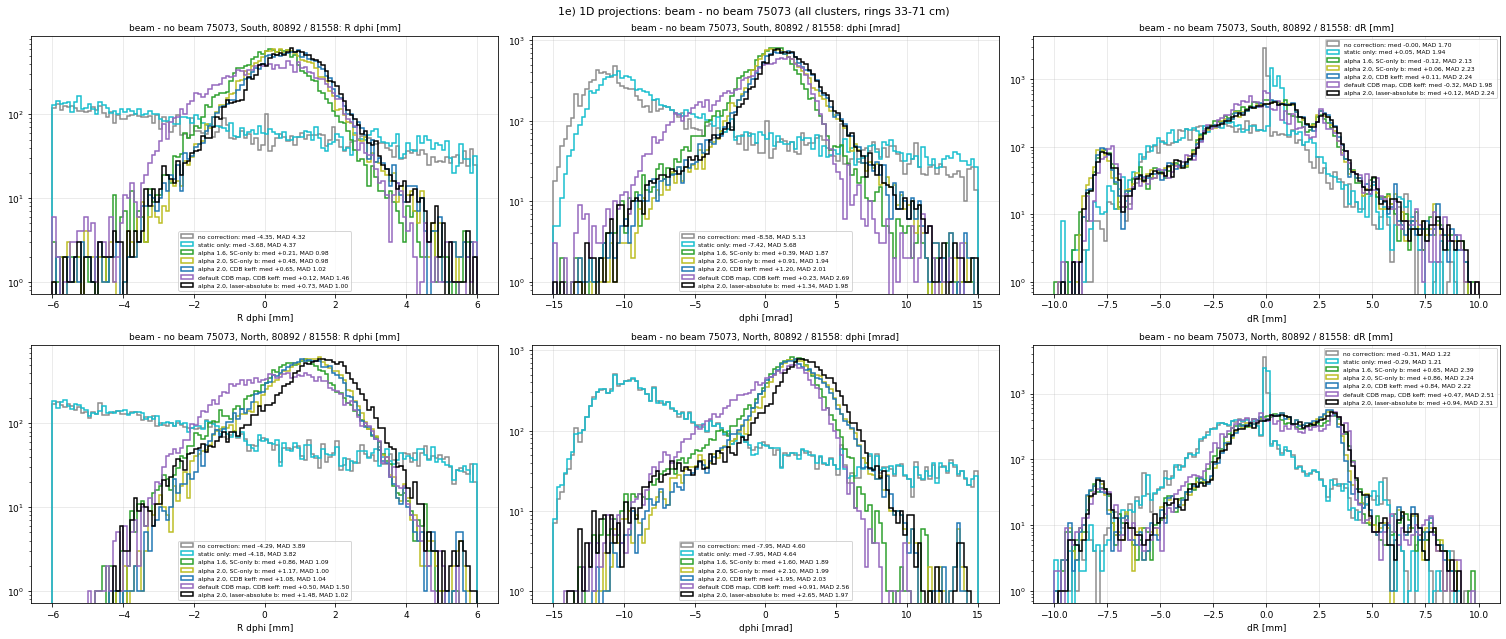

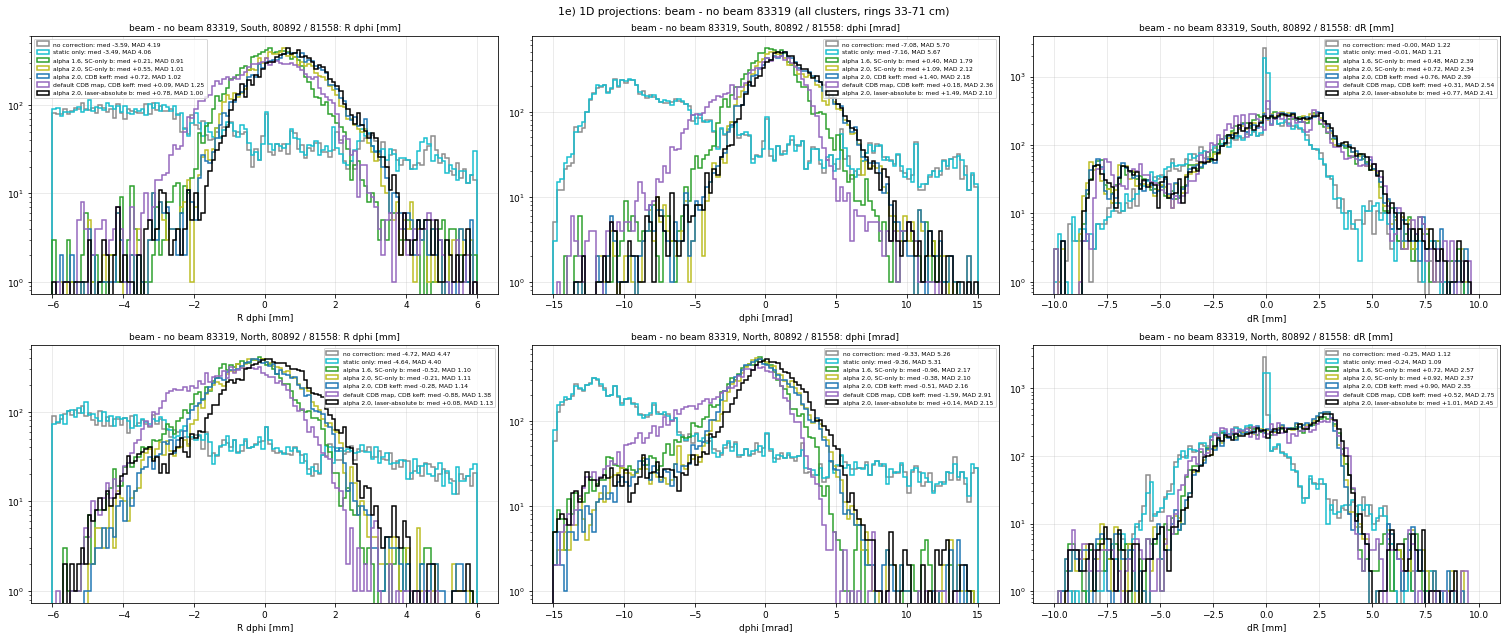

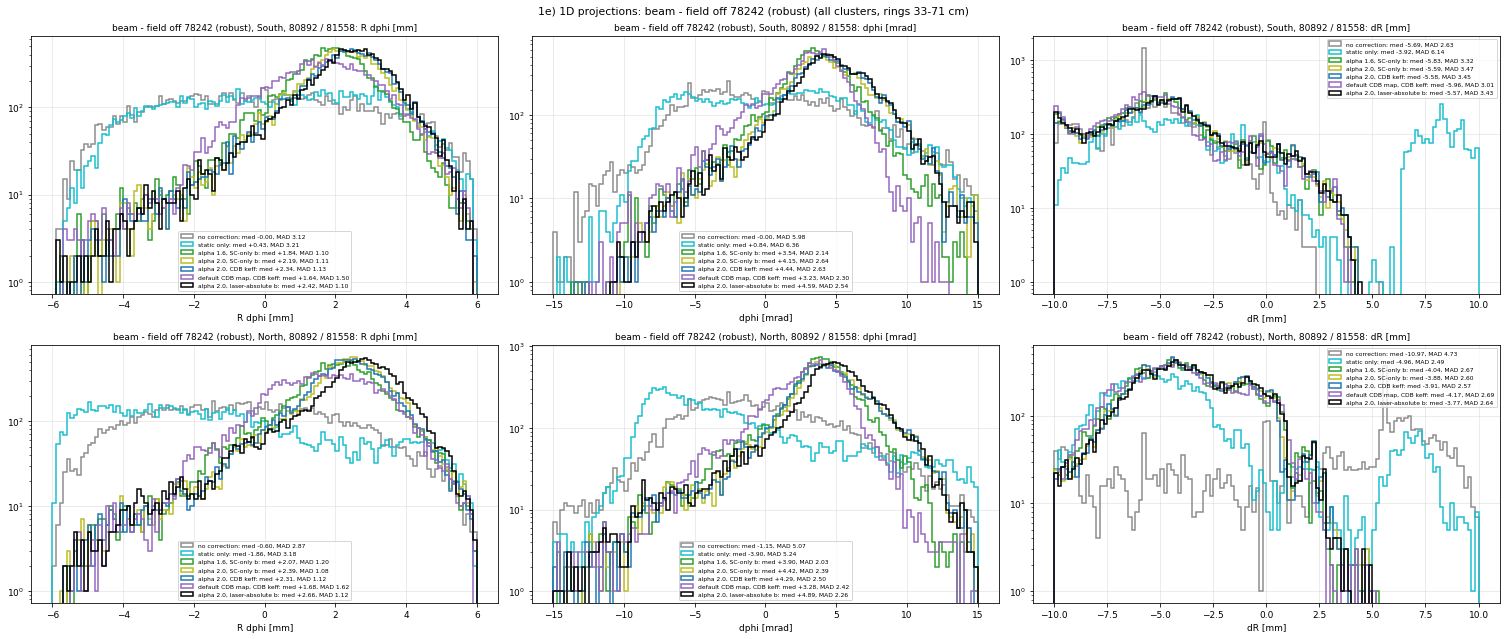

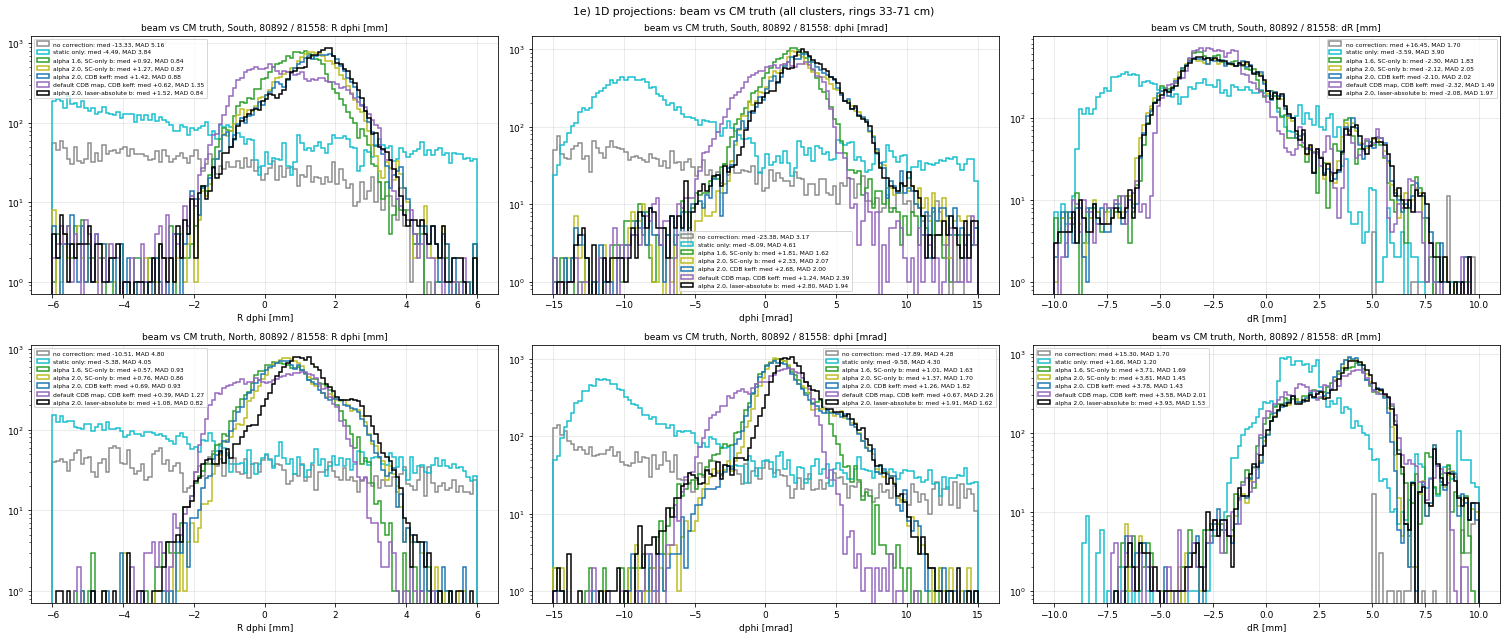

In [6]:
show(sp.sec1_hists())
show(sp.sec1_hists(lumi='high'))

## 2. Gain structure in beam − no beam
The sector sagitta in beam − no beam for α 1.6 / α 2.0 at the space-charge-only b, α 2.0 and the default CDB map at the
CDB keff, the laser-absolute b, and the pinned map. Then the per-sector Δφ / dR / RΔφ profiles. **To rerun:** the module fit
with `REFERENCE = "nobeam"` at the space-charge b and α from section 1, then its validation scan.

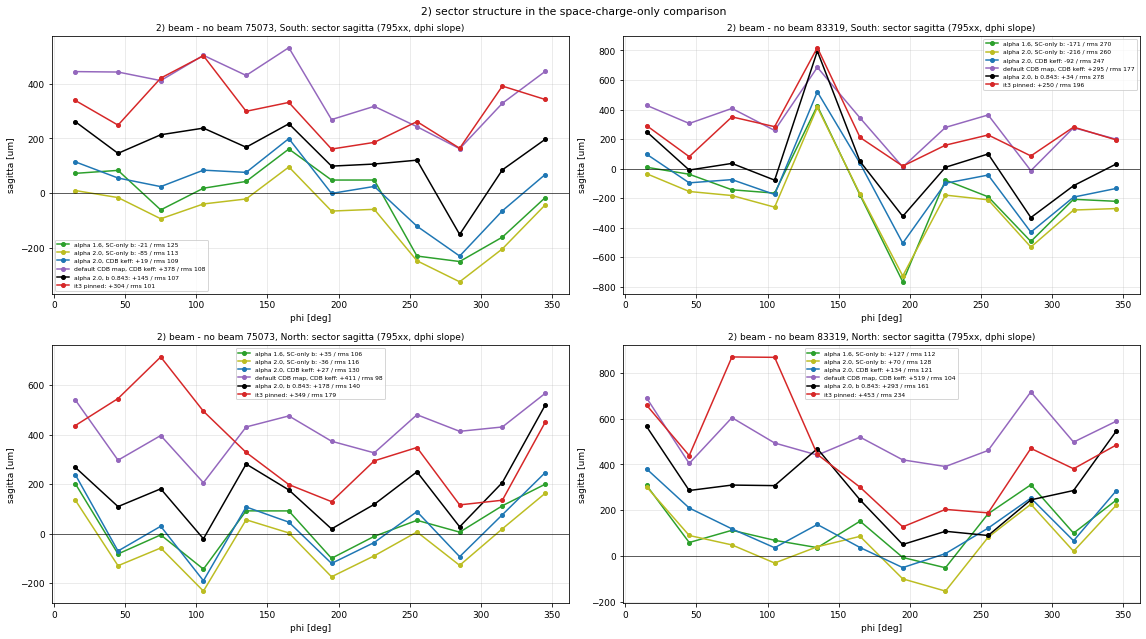

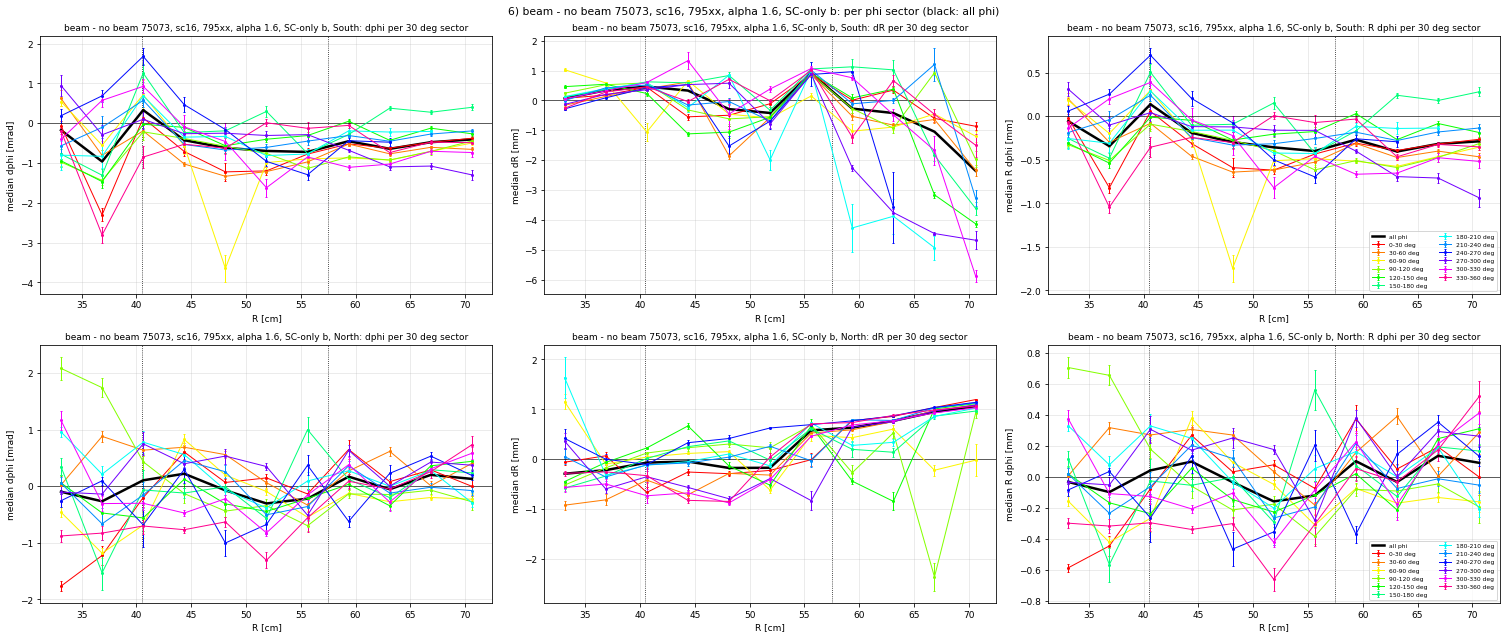

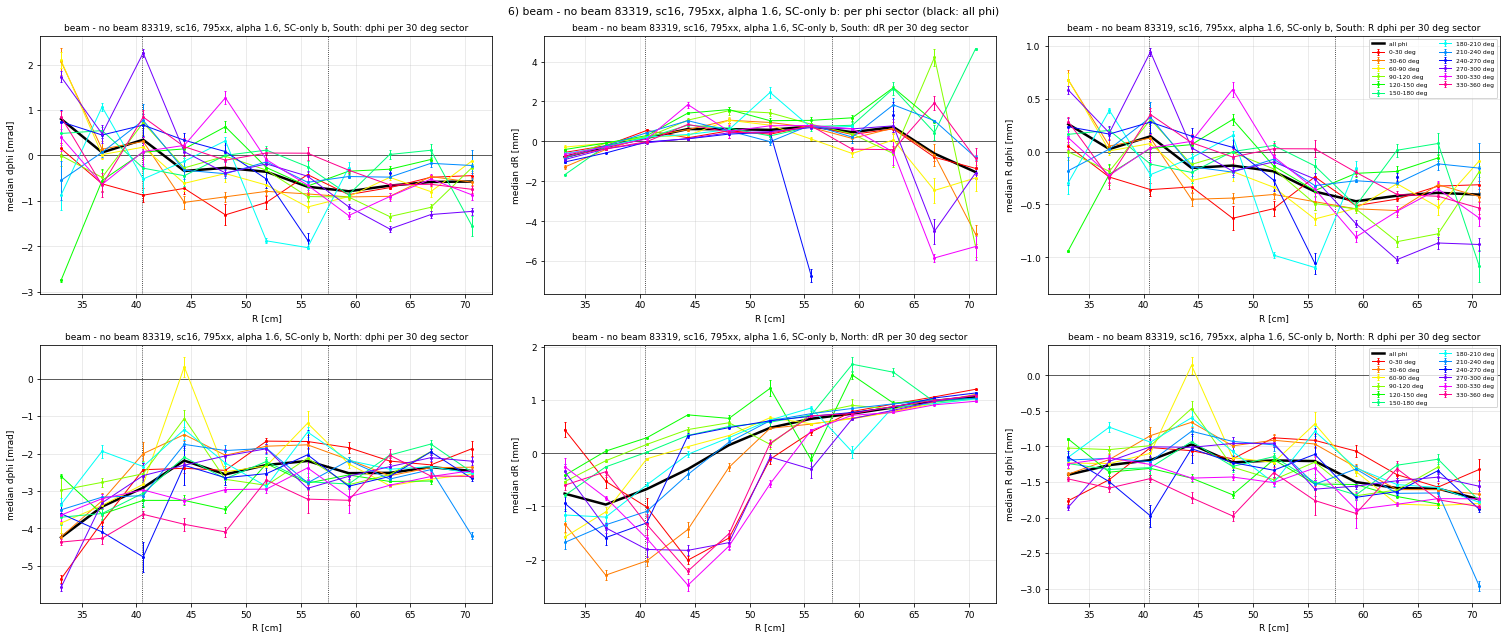

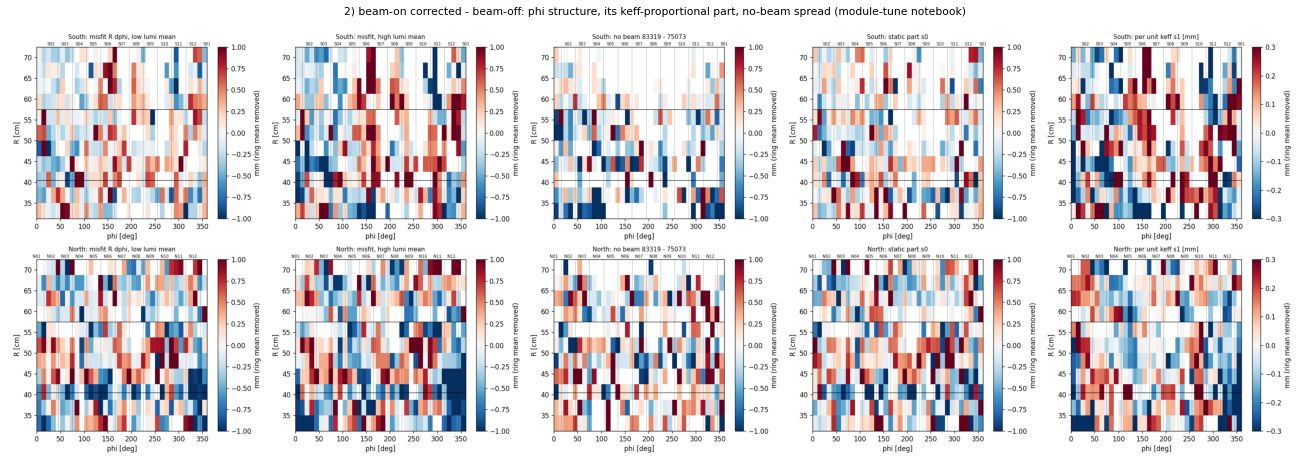

In [7]:
f, ST = sp.sec2_structure(); show(f)

## 3. Static model at the space-charge keff
- **3a.** No beam, static correction only, vs field off and vs truth: the static model's leftover directly, with no
  space charge at all.
- **3b.** Beam at the space-charge keff vs truth / field off / no beam.
- Then per-sector profiles and the static scans (tilt, z, IFC).

Whatever remains here beyond the no-beam comparison is static, and is pinned with tilt, z, IFC and the frames, not with
keff.

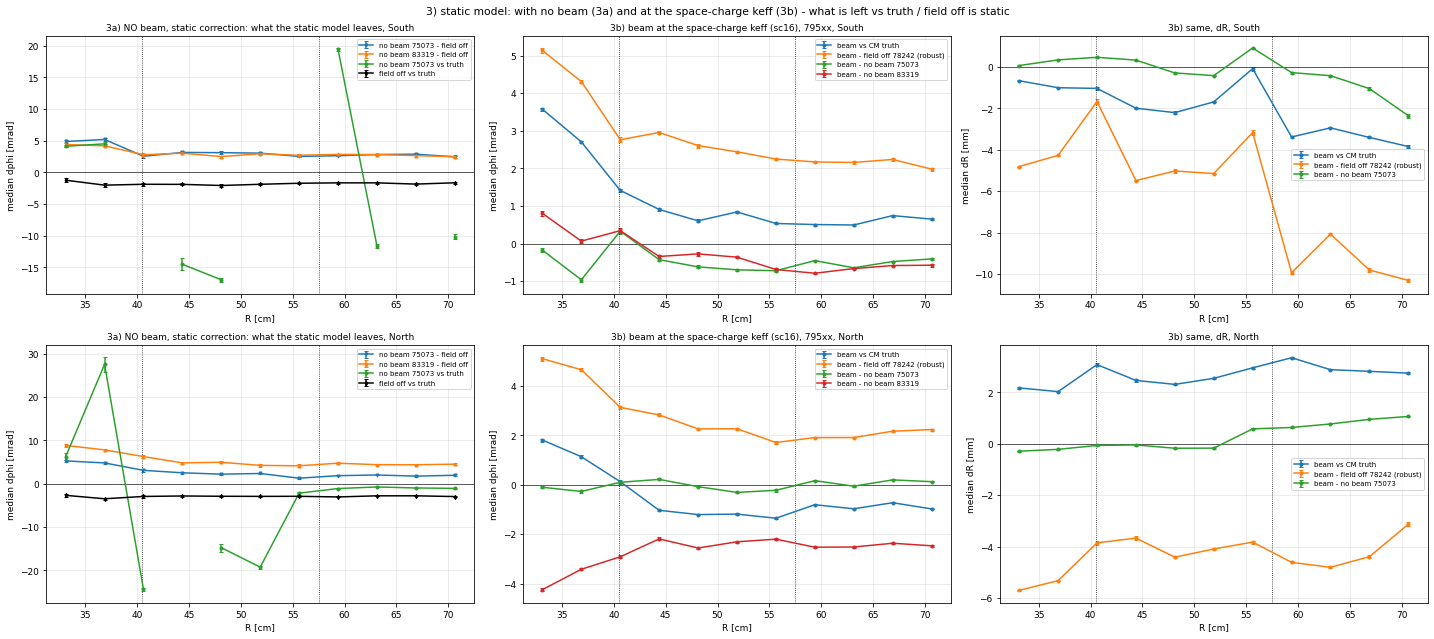

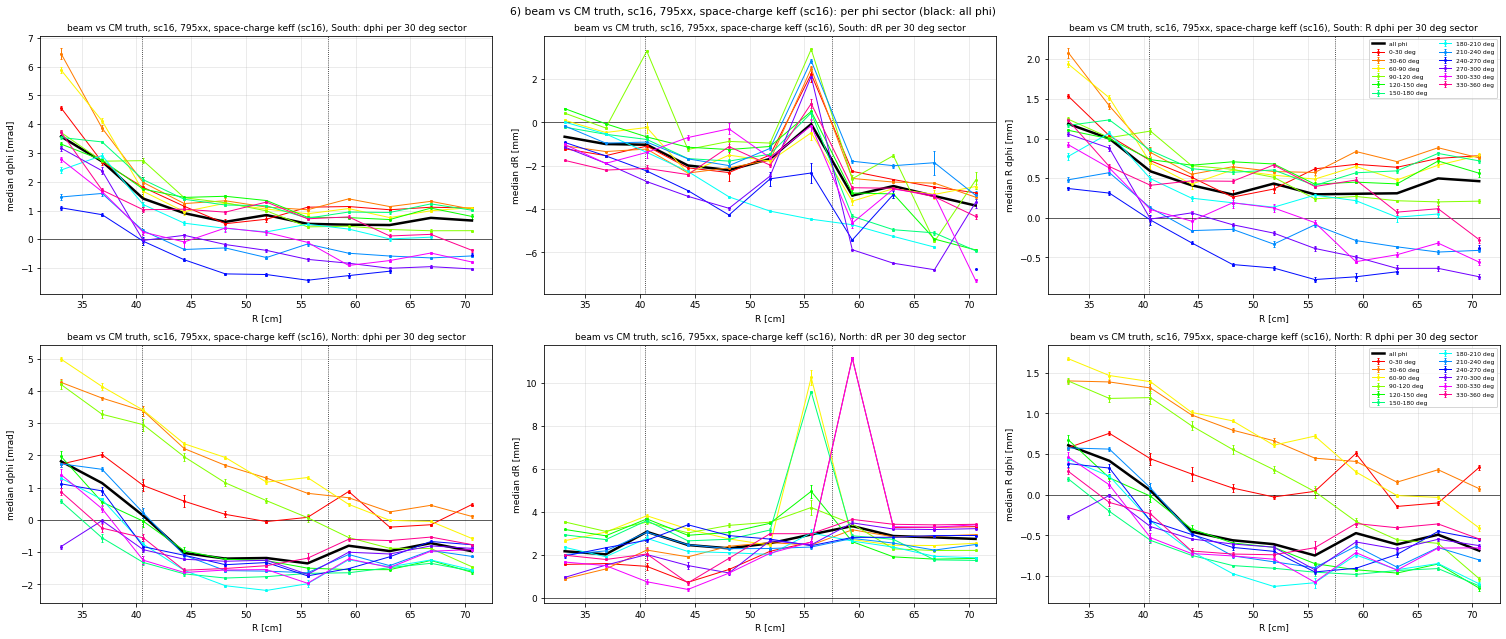

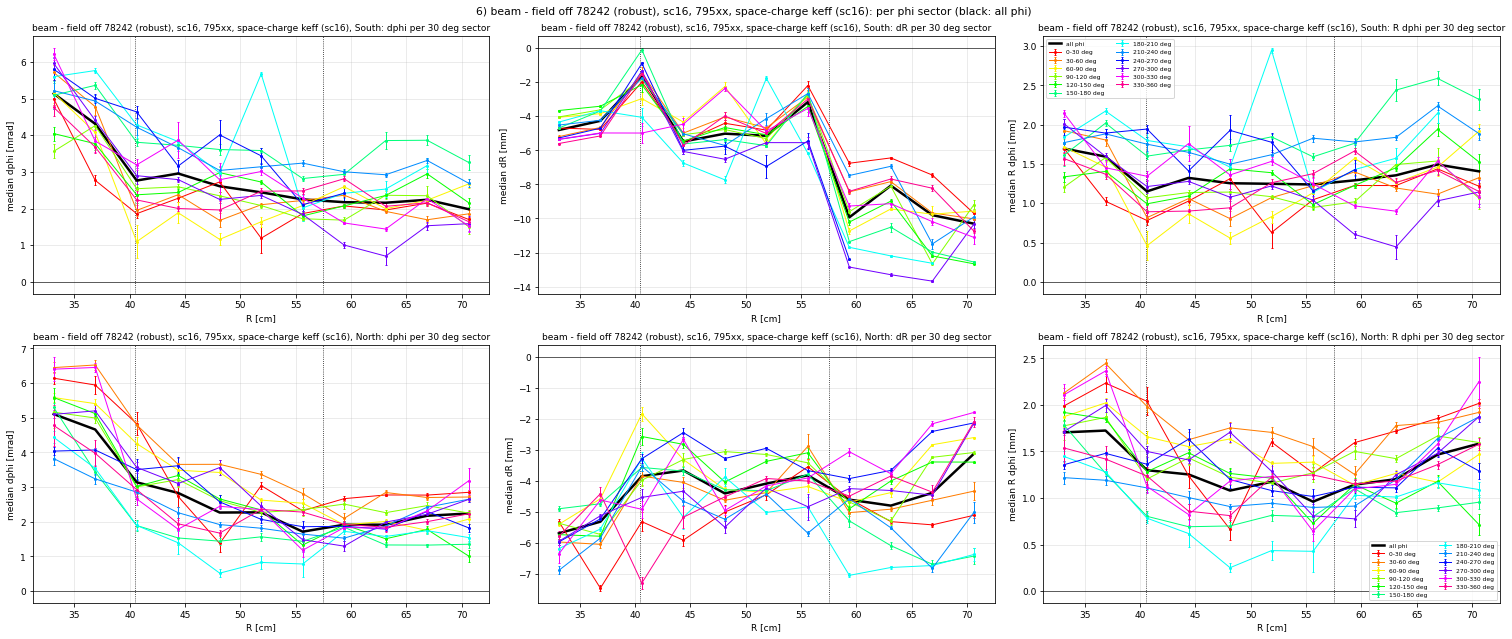

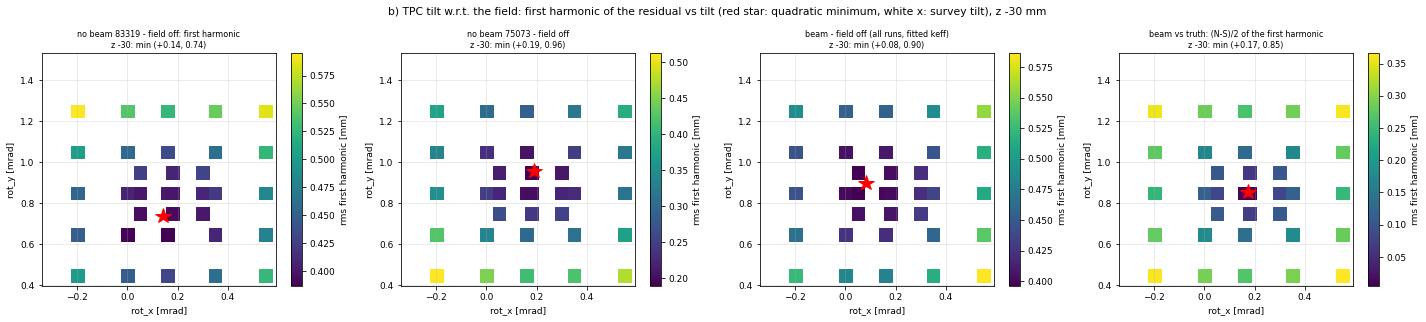

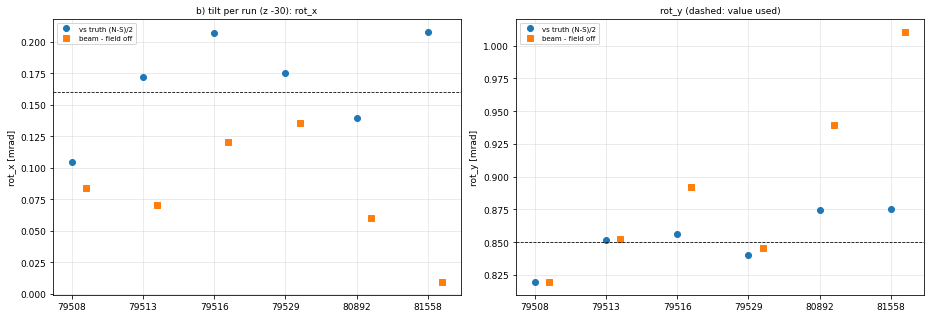

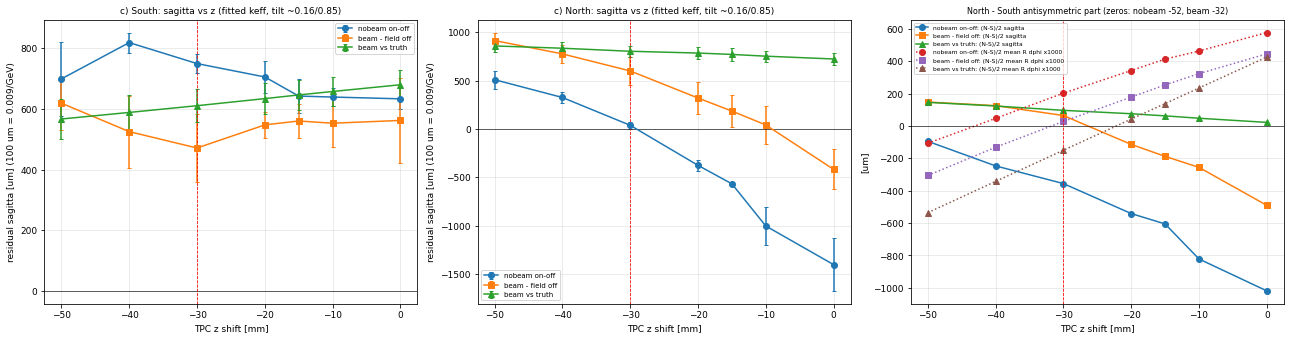

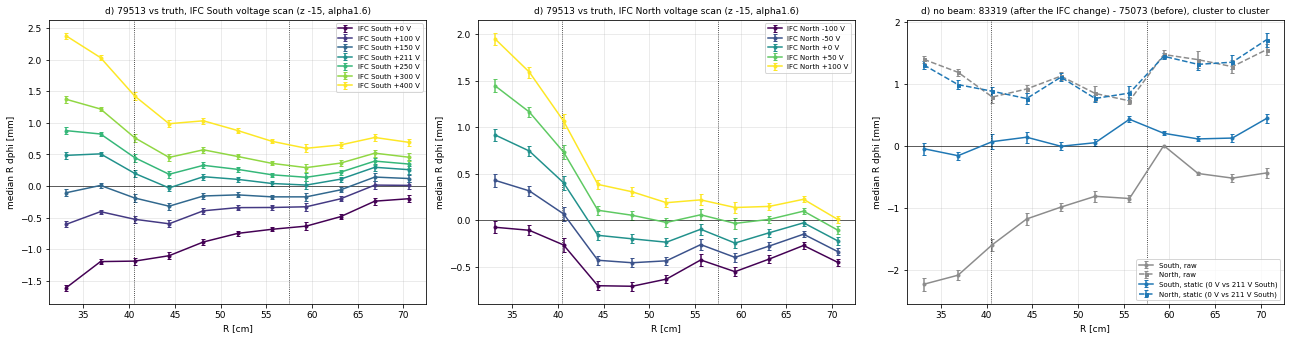

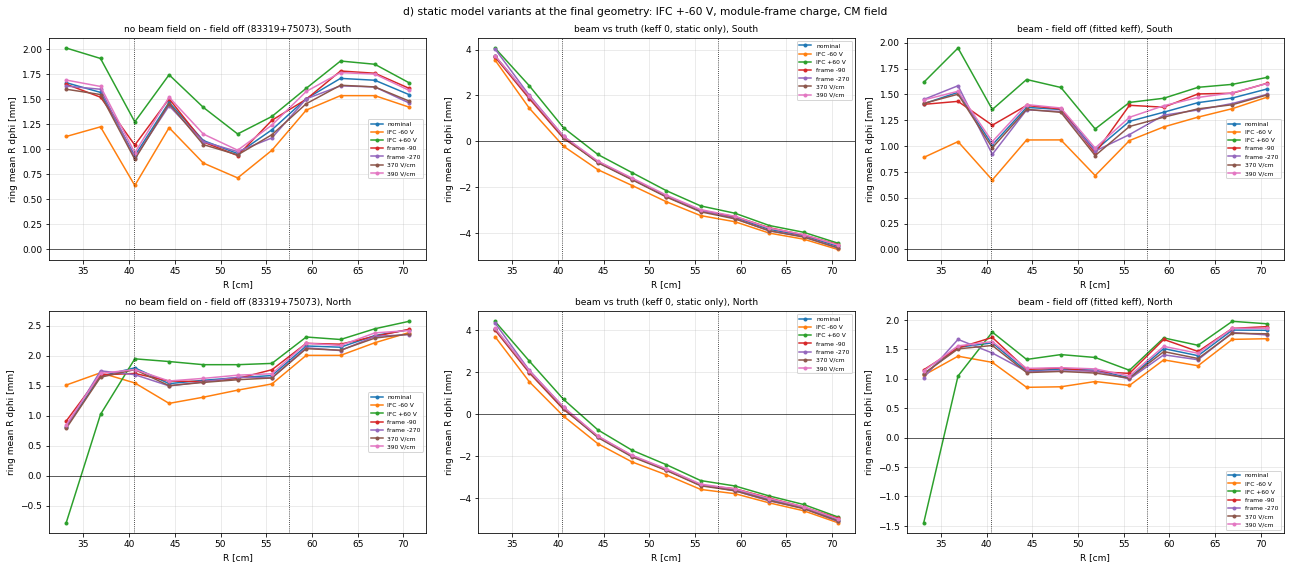

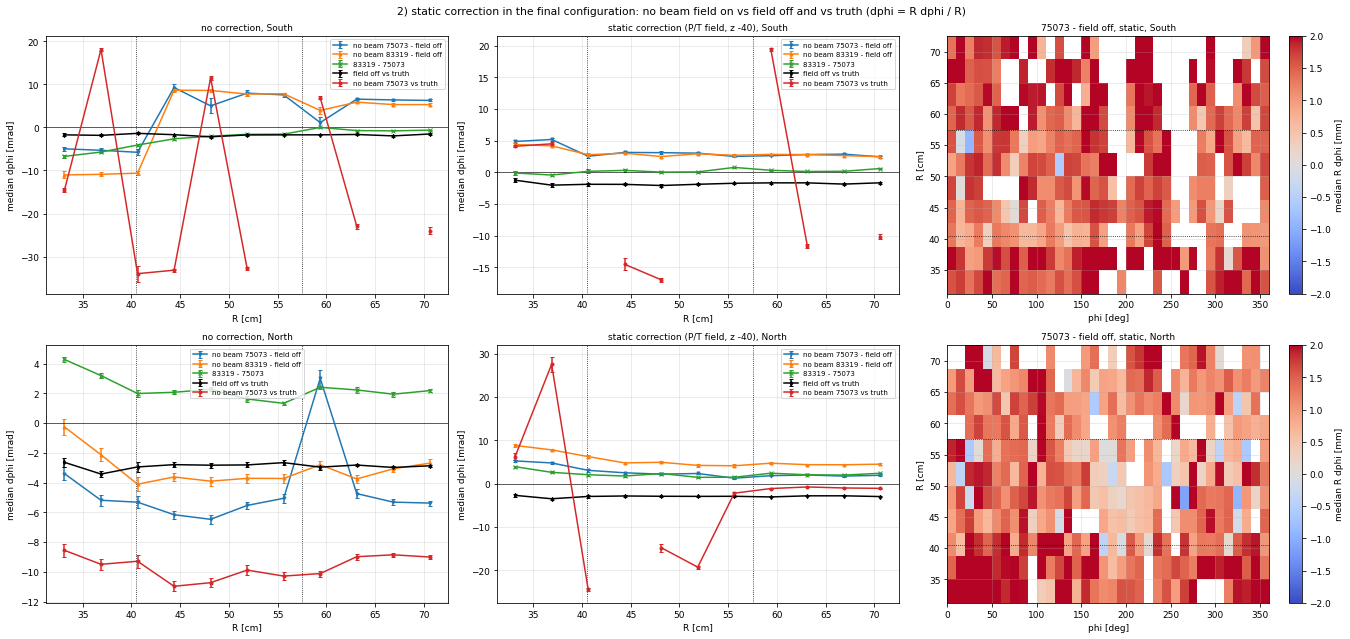

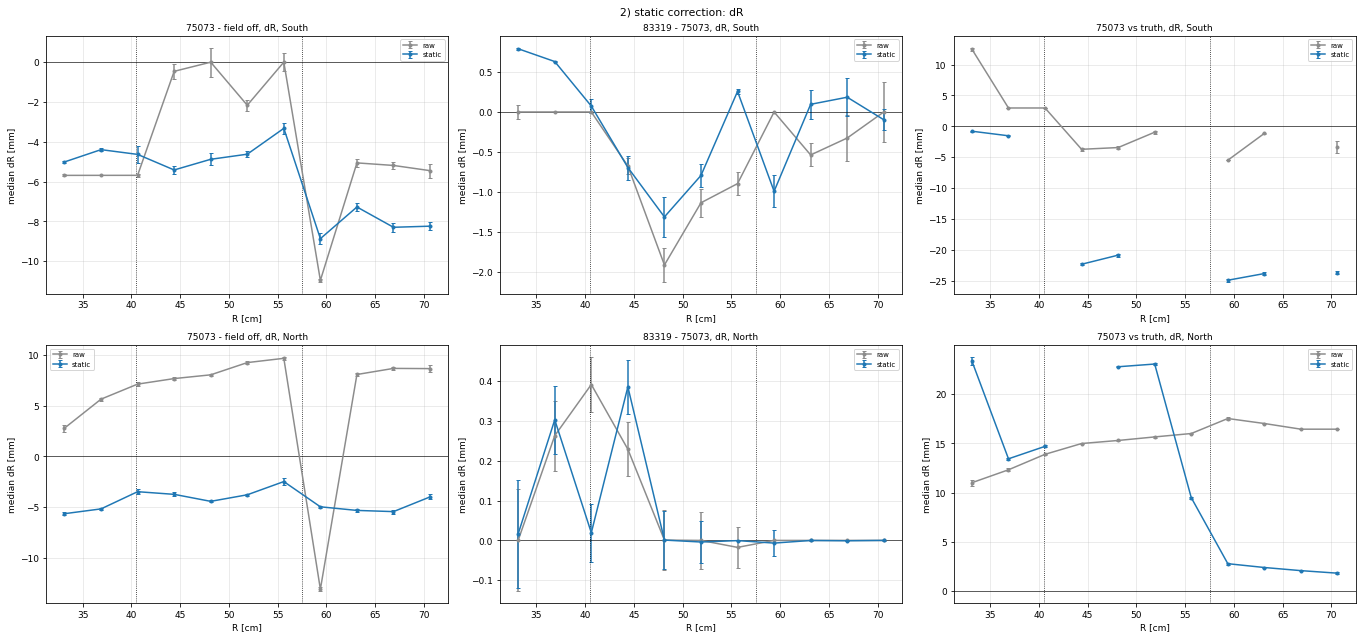

stage used for the space-charge keff: sc16
  T              South: DCA +5.36 mm (free quadratic)  sagitta  -284 um (dphi slope)
  T              North: DCA +5.93 mm (free quadratic)  sagitta  -116 um (dphi slope)
  OFF            South: DCA +4.15 mm (free quadratic)  sagitta  -299 um (dphi slope)
  OFF            North: DCA +6.18 mm (free quadratic)  sagitta  -307 um (dphi slope)
  NB75           South: DCA +0.86 mm (free quadratic)  sagitta    -6 um (dphi slope)
  NB75           North: DCA +0.35 mm (free quadratic)  sagitta   +45 um (dphi slope)
  NBOFF_static   South: DCA +3.93 mm (free quadratic)  sagitta  -229 um (dphi slope)
  NBT_static     South: DCA +8.69 mm (free quadratic)  sagitta -1215 um (dphi slope)
  OFFT_static    South: DCA +0.70 mm (free quadratic)  sagitta   +29 um (dphi slope)
  NBOFF_static   North: DCA +5.75 mm (free quadratic)  sagitta  -362 um (dphi slope)
  NBT_static     North: DCA -11.22 mm (free quadratic)  sagitta +2151 um (dphi slope)
  OFFT_static    Nort

In [8]:
f, rows, st = sp.sec3_static(); show(f)
print(f"stage used for the space-charge keff: {st}")
for k, s, d, sg in rows:
    print(f"  {k:14s} {c.SIDES[s]:5s}: DCA {d:+.2f} mm (free quadratic)  sagitta {sg:+5.0f} um (dphi slope)")

## 4. Tracks
keff₀ (charge-odd rDCA0 = 0) per |η| from the 79513 keff scan (α 2.0), next to the CDB keff and the laser-absolute b.

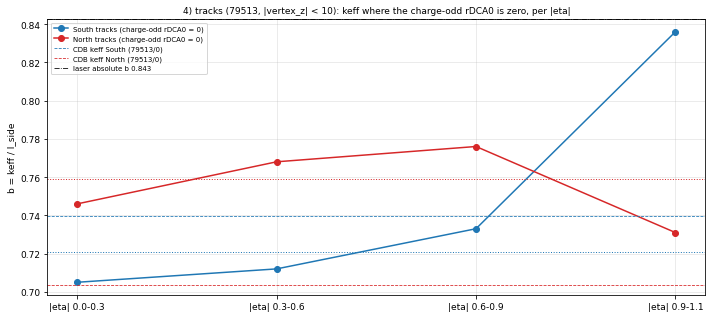

In [9]:
show(sp.sec4_tracks())

## 5. What to rerun next
1. **Space-charge map shape.** α 1.6 fits beam − no beam best. Check α between 1.6 and 2.0 (`MixMaps.C`, no new
   Rossegger runs), and the inner turn-on (r0, width), which sets 30–33 cm where the CM has no stripes.
2. **keff.** Is one b for all runs (high lumi included) linear in the current? Set the production keff = b × I_side with
   that b and the α of step 1.
3. **Gain structure.** Module fit vs no beam at that α and b (`TPC_PHGarfield_ModuleGainTune_v35`, `REFERENCE =
   "nobeam"`, `PIN_ABSOLUTE = False`), then validation.
4. **Static model.** At the space-charge keff, the leftover vs field off / truth (section 3): tilt, z, IFC, frames, and
   the field-on vs field-off offset.
5. **Tracks.** Track keff scan with the step 1–3 map: charge balance, rDCA0 per |η|.
6. **Default CDB map at the CDB keff** (`cdbmap` jobs): `make_v2_cdb.py build`, then rerun this notebook.